<div dir="rtl">

# تمرین ۴ — کاربرد CLIP: جستجوی معنایی و تفسیر هوشمند داده‌های پزشکی

**هدف:** استفاده از توانایی CLIP در **Zero-Shot Classification** و **Image-Text Retrieval** برای ساخت سیستمی که تصاویر شبکیه (Fundus)
را نه فقط طبقه‌بندی کند، بلکه بر اساس **توصیف‌های متنیِ پیچیده‌ی پزشکی** (و نه برچسب‌های تک‌کلمه‌ای) تحلیل و جستجو کند.

ساختار نوت‌بوک مطابق صورت تمرین:

1. **بخش اول:** مجموعه داده (DeepDRiD — تصاویر شبکیه با درجه‌ی رتینوپاتی دیابتی) و جدا کردن تصاویر **پرس‌وجو (Query)** از **گالری**
2. **بخش دوم:** بارگذاری CLIP و استخراج بردار ویژگی تصاویر
3. **بخش سوم:** تعریف پرامپت‌های متنی (برچسب ساده / جمله‌ی توصیفی پزشکی / مجموعه‌ای از جمله‌ها)
4. **بخش چهارم:** تشخیص Zero-Shot با شباهت کسینوسی و `softmax`
5. **بخش پنجم:** جستجوی معنایی متن → تصویر (Text-to-Image Retrieval)
6. **بخش ششم:** جستجوی تصویر → تصویر و مقایسه با روش‌های نظارت‌شده روی ویژگی‌های CLIP
7. **جمع‌بندی**

هیچ آموزشی انجام نمی‌شود؛ وزن‌های CLIP ثابت‌اند و کل نوت‌بوک روی CPU در حدود ۳ دقیقه اجرا می‌شود.

</div>

<div dir="rtl">

## ۰. کتابخانه‌ها و تنظیمات کلی

</div>

In [1]:
import os, subprocess, time, textwrap, urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import torch
import torch.nn.functional as F
import open_clip

from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                             cohen_kappa_score, roc_auc_score, confusion_matrix,
                             classification_report, average_precision_score)
from sklearn.linear_model import LogisticRegression

# ---------------- Global configuration ----------------
DATA_ROOT   = "DeepDRiD"                      # dataset folder (cloned automatically if missing)
DATA_URL    = "https://github.com/deepdrdoc/DeepDRiD.git"
IMG_ROOT    = os.path.join(DATA_ROOT, "regular_fundus_images")

MODEL_NAME  = "ViT-B-32-quickgelu"            # CLIP ViT-B/32 architecture (same as the original OpenAI model)
WEIGHTS     = "weights/vit_b_32-quickgelu-laion400m_e32-46683a32.pt"
WEIGHTS_URL = ("https://github.com/mlfoundations/open_clip/releases/download/"
               "v0.2-weights/vit_b_32-quickgelu-laion400m_e32-46683a32.pt")
# To use the original OpenAI weights instead (needs access to the OpenAI / HuggingFace servers):
#   WEIGHTS = "openai"

OUT_DIR     = "outputs"
BATCH_SIZE  = 32
SEED        = 42
GRADE_NAMES = ["No DR", "Mild NPDR", "Moderate NPDR", "Severe NPDR", "PDR"]

os.makedirs(OUT_DIR, exist_ok=True)
np.random.seed(SEED); torch.manual_seed(SEED)
device = "cuda" if torch.cuda.is_available() else "cpu"
plt.rcParams.update({"figure.dpi": 70, "savefig.dpi": 110, "savefig.bbox": "tight"})
print("torch", torch.__version__, "| open_clip", open_clip.__version__, "| device:", device)

torch 2.15.0+cu132 | open_clip 4.2.1 | device: cpu


<div dir="rtl">

## بخش اول: مجموعه داده و جدا کردن تصاویر پرس‌وجو

### ۱.۱ دیتاست DeepDRiD

**DeepDRiD** (Deep Diabetic Retinopathy Image Dataset، چالش ISBI-2020) یک مجموعه داده‌ی استاندارد تصاویر رنگی شبکیه است. برای هر چشم دو تصویر
وجود دارد و هر تصویر توسط چشم‌پزشک با **درجه‌ی بین‌المللی رتینوپاتی دیابتی (۰ تا ۴)** برچسب خورده است:

| درجه | نام | علائم بالینی |
|---|---|---|
| ۰ | No DR | شبکیه‌ی سالم |
| ۱ | Mild NPDR | فقط میکروآنوریسم |
| ۲ | Moderate NPDR | خونریزی‌های نقطه‌ای/لکه‌ای، اگزودای سخت |
| ۳ | Severe NPDR | خونریزی گسترده در چهار ربع، Venous beading، IRMA |
| ۴ | PDR | نورگ‌زایی (Neovascularization)، خونریزی زجاجیه/پیش‌شبکیه‌ای |

علاوه بر درجه‌ی بیماری، ستون `Overall quality` (کیفیت مناسب/نامناسب برای تشخیص) هم وجود دارد که در بخش جستجوی معنایی از آن استفاده می‌کنیم.
اگر پوشه‌ی دیتاست کنار نوت‌بوک نباشد، سلول زیر فقط دو زیرپوشه‌ی لازم را از مخزن رسمی دیتاست دریافت می‌کند.

</div>

In [2]:
if not os.path.isdir(IMG_ROOT):
    # sparse clone: download only the regular fundus training/validation folders (~0.8 GB)
    subprocess.run(["git", "clone", "--depth", "1", "--filter=blob:none", "--sparse", DATA_URL, DATA_ROOT], check=True)
    subprocess.run(["git", "-C", DATA_ROOT, "sparse-checkout", "set",
                    "regular_fundus_images/regular-fundus-training",
                    "regular_fundus_images/regular-fundus-validation"], check=True)

frames = []
for split in ["training", "validation"]:
    folder = os.path.join(IMG_ROOT, f"regular-fundus-{split}")
    d = pd.read_csv(os.path.join(folder, f"regular-fundus-{split}.csv"))
    d["official_split"] = split
    d["path"] = [os.path.join(folder, "Images", str(p), f"{i}.jpg") for p, i in zip(d.patient_id, d.image_id)]
    frames.append(d)
df = pd.concat(frames, ignore_index=True)

# every image belongs to one eye -> its label is in the left OR the right column
df["grade"]   = df["left_eye_DR_Level"].fillna(df["right_eye_DR_Level"]).astype(int)
df["eye"]     = np.where(df["left_eye_DR_Level"].notna(), "left", "right")
df["quality"] = df["Overall quality"].astype(int)          # 1 = good enough for diagnosis, 0 = not
assert all(os.path.exists(p) for p in df.path), "some image files are missing"

print("images:", len(df), "| patients:", df.patient_id.nunique(), "| image size:", Image.open(df.path[0]).size)
df[["patient_id", "image_id", "eye", "grade", "quality", "official_split"]].head()

images: 1600 | patients: 400 | image size: (1736, 1824)


,patient_id,image_id,eye,grade,quality,official_split
0,1,1_l1,left,0,0,training
1,1,1_l2,left,0,0,training
2,1,1_r1,right,0,0,training
3,1,1_r2,right,0,0,training
4,2,2_l1,left,2,0,training


<div dir="rtl">

### ۱.۲ جدا کردن پرس‌وجوها (Query) از گالری (Gallery)

چون CLIP به‌صورت Zero-Shot استفاده می‌شود، به داده‌ی آموزشی نیاز نداریم؛ اما مطابق صورت تمرین تعدادی از تصاویر را به‌عنوان **پرس‌وجو** جدا می‌کنیم:

- **Query (۴۰۰ تصویر، ۱۰۰ بیمار):** بخش `validation` رسمی دیتاست — تشخیص Zero-Shot روی این تصاویر ارزیابی می‌شود و در جستجوی تصویر → تصویر نقش پرس‌وجو را دارند.
- **Gallery (۱۲۰۰ تصویر، ۳۰۰ بیمار):** بخش `training` رسمی — پایگاه تصاویری که جستجوی متن → تصویر و تصویر → تصویر در آن انجام می‌شود.

تقسیم در سطح **بیمار** است؛ یعنی هیچ بیماری هم‌زمان در Query و Gallery نیست (جلوگیری از نشت داده در جستجوی تصویر → تصویر).

</div>

In [3]:
is_query   = (df.official_split == "validation").values
is_gallery = ~is_query
assert not set(df.patient_id[is_query]) & set(df.patient_id[is_gallery])   # no shared patients

dist = pd.DataFrame({
    "Gallery": df.grade[is_gallery].value_counts().sort_index(),
    "Query":   df.grade[is_query].value_counts().sort_index(),
})
dist.index = [f"{g} - {n}" for g, n in enumerate(GRADE_NAMES)]
dist.loc["Total"] = dist.sum()
dist["Query %"] = (100 * dist["Query"] / dist.loc["Total", "Query"]).round(1)
print("poor-quality images: gallery = %d, query = %d" % ((df.quality[is_gallery] == 0).sum(), (df.quality[is_query] == 0).sum()))
dist

poor-quality images: gallery = 624, query = 218


,Gallery,Query,Query %
0 - No DR,540,174,43.5
1 - Mild NPDR,140,46,11.5
2 - Moderate NPDR,234,92,23.0
3 - Severe NPDR,214,68,17.0
4 - PDR,72,20,5.0
Total,1200,400,100.0


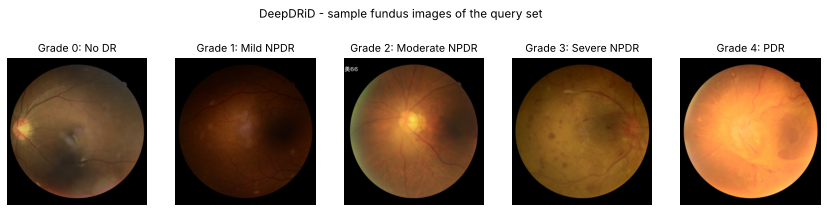

In [4]:
# one random query image per DR grade
rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(1, 5, figsize=(15, 3.4))
for g, ax in enumerate(axes):
    idx = rng.choice(np.where(is_query & (df.grade.values == g))[0])
    ax.imshow(Image.open(df.path[idx]).resize((336, 353)))
    ax.set_title(f"Grade {g}: {GRADE_NAMES[g]}", fontsize=11); ax.axis("off")
plt.suptitle("DeepDRiD - sample fundus images of the query set", y=1.02)
plt.savefig(f"{OUT_DIR}/samples.png"); plt.show()

<div dir="rtl">

## بخش دوم: مدل CLIP و استخراج ویژگی تصاویر

CLIP از دو رمزگذار تشکیل شده است: یک **رمزگذار تصویر** (در اینجا ViT-B/32) و یک **رمزگذار متن** (Transformer). هر دو خروجی خود را به یک
**فضای مشترک ۵۱۲ بعدی** نگاشت می‌کنند و مدل با زیان Contrastive روی صدها میلیون زوج (تصویر، متن) آموزش دیده است تا بردار تصویر و بردار
متنِ متناظرش به هم نزدیک شوند. بنابراین «شباهت کسینوسی بین بردار تصویر و بردار یک جمله» معیار تطابق آن دو است و می‌توان بدون هیچ آموزشی،
طبقه‌بندی (مقایسه‌ی تصویر با چند جمله) و جستجو (مقایسه‌ی جمله با چند تصویر) انجام داد.

**وزن‌ها:** از پیاده‌سازی `open_clip` با معماری ViT-B/32 (همان معماری CLIP اصلی) و وزن‌های آموزش‌دیده روی LAION-400M استفاده شده است
(فایل وزن در صورت نبودن، خودکار دانلود می‌شود). با `WEIGHTS = "openai"` می‌توان وزن‌های اصلی OpenAI را هم بارگذاری کرد.

</div>

In [5]:
if WEIGHTS != "openai" and not os.path.exists(WEIGHTS):
    os.makedirs(os.path.dirname(WEIGHTS), exist_ok=True)
    print("downloading CLIP weights (~600 MB) ...")
    urllib.request.urlretrieve(WEIGHTS_URL, WEIGHTS)

model, _, preprocess = open_clip.create_model_and_transforms(MODEL_NAME, pretrained=WEIGHTS)
tokenizer = open_clip.get_tokenizer(MODEL_NAME)
model = model.to(device).eval()

n_params = sum(p.numel() for p in model.parameters())
print(f"model: {MODEL_NAME} | parameters: {n_params/1e6:.1f} M | embedding dim: {model.visual.output_dim}")
print(f"logit scale (1/temperature): {model.logit_scale.exp().item():.1f}")
print("image preprocessing:", preprocess)

model: ViT-B-32-quickgelu | parameters: 151.3 M | embedding dim: 512
logit scale (1/temperature): 100.0
image preprocessing: Compose(
    Resize(size=224, interpolation=bicubic, max_size=None, antialias=True)
    CenterCrop(size=(224, 224))
    MaybeConvertMode()
    MaybeToTensor()
    Normalize(mean=(0.48145466, 0.4578275, 0.40821073), std=(0.26862954, 0.26130258, 0.27577711))
)


<div dir="rtl">

### ۲.۱ بردار ویژگی همه‌ی تصاویر

هر تصویر با پیش‌پردازش استاندارد CLIP (تغییر اندازه به ۲۲۴، برش مرکزی، نرمال‌سازی) به مدل داده می‌شود و بردار خروجی **L2-نرمال** می‌شود تا
ضرب داخلی دو بردار همان شباهت کسینوسی باشد. بردارها یک بار محاسبه و در `outputs/image_embeddings.npy` ذخیره می‌شوند (حدود ۲ دقیقه روی CPU).

</div>

In [6]:
@torch.no_grad()
def encode_images(paths):
    """Return L2-normalised CLIP image embeddings (N x 512) for a list of image files."""
    feats = []
    for i in range(0, len(paths), BATCH_SIZE):
        batch = torch.stack([preprocess(Image.open(p).convert("RGB")) for p in paths[i:i + BATCH_SIZE]]).to(device)
        feats.append(F.normalize(model.encode_image(batch), dim=-1).cpu())
    return torch.cat(feats).numpy()

@torch.no_grad()
def encode_texts(sentences):
    """Return L2-normalised CLIP text embeddings (N x 512) for a list of sentences."""
    tokens = tokenizer(list(sentences)).to(device)
    return F.normalize(model.encode_text(tokens), dim=-1).cpu().numpy()

EMB_FILE = f"{OUT_DIR}/image_embeddings.npy"
if os.path.exists(EMB_FILE) and len(np.load(EMB_FILE)) == len(df):
    img_emb = np.load(EMB_FILE); print("embeddings loaded from cache")
else:
    t0 = time.time()
    img_emb = encode_images(df.path.tolist())
    np.save(EMB_FILE, img_emb)
    print(f"encoded {len(df)} images in {time.time() - t0:.0f} s")

y       = df.grade.values
emb_q,  y_q = img_emb[is_query],   y[is_query]
emb_g,  y_g = img_emb[is_gallery], y[is_gallery]
df_q, df_g  = df[is_query].reset_index(drop=True), df[is_gallery].reset_index(drop=True)
print("query:", emb_q.shape, "| gallery:", emb_g.shape)

encoded 1600 images in 112 s
query: (400, 512) | gallery: (1200, 512)


<div dir="rtl">

## بخش سوم: تعریف پرامپت‌های متنی

برای هر یک از ۵ درجه‌ی بیماری سه نوع «برچسب متنی» تعریف می‌کنیم تا اثر توصیف پزشکی را بسنجیم:

- **A — برچسب ساده:** جمله‌های کوتاه به سبک `a photo of ...` (روش معمول Zero-Shot).
- **B — جمله‌ی توصیفی پزشکی:** برای هر کلاس یک جمله که علائم بالینی همان درجه را (آن‌طور که در متون چشم‌پزشکی می‌آید) توصیف می‌کند؛ سه جمله‌ی
  نمونه‌ی صورت تمرین هم در همین فهرست هستند.
- **C — مجموعه‌ی توصیف‌ها (Prompt Ensemble):** برای هر کلاس سه جمله‌ی توصیفی متفاوت؛ بردار کلاس، میانگینِ نرمال‌شده‌ی بردار این جمله‌ها است.

</div>

In [7]:
# A) simple label prompts
PROMPTS_SIMPLE = [
    "a photo of a healthy retina",
    "a photo of mild retinopathy",
    "a photo of moderate retinopathy",
    "a photo of severe retinopathy",
    "a photo of proliferative retinopathy",
]

# B) one descriptive medical sentence per class
PROMPTS_DESC = [
    "A healthy retina with clear optic disc and blood vessels",
    "A fundus image showing mild non-proliferative diabetic retinopathy with a few microaneurysms",
    "A fundus image showing moderate non-proliferative diabetic retinopathy with dot and blot hemorrhages and hard exudates",
    "A fundus image showing severe non-proliferative diabetic retinopathy with extensive retinal hemorrhages, venous beading and cotton wool spots",
    "A fundus image showing severe proliferative diabetic retinopathy with neovascularization",
]

# C) several descriptive sentences per class (prompt ensemble)
PROMPTS_ENSEMBLE = [
    [PROMPTS_DESC[0],
     "A normal fundus photograph with no hemorrhages, no exudates and no signs of diabetic retinopathy",
     "A color fundus image of a normal eye with a sharp optic disc margin and a clean macula"],
    [PROMPTS_DESC[1],
     "An image of the eye showing signs of microaneurysms",
     "A retina with only a few small red dots, the earliest sign of diabetic retinopathy"],
    [PROMPTS_DESC[2],
     "A retinal photograph with scattered hemorrhages, microaneurysms and yellow hard exudates",
     "A fundus image of diabetic retinopathy with several retinal hemorrhages and lipid exudates near the macula"],
    [PROMPTS_DESC[3],
     "A retina with numerous hemorrhages in all four quadrants and intraretinal microvascular abnormalities",
     "A fundus photograph of advanced diabetic retinopathy with many blot hemorrhages and cotton wool spots but no new vessels"],
    [PROMPTS_DESC[4],
     "A retina with abnormal new blood vessels on the optic disc, preretinal hemorrhage and fibrous proliferation",
     "A fundus photograph of proliferative diabetic retinopathy with vitreous hemorrhage and laser photocoagulation scars"],
]

txt_simple = encode_texts(PROMPTS_SIMPLE)
txt_desc   = encode_texts(PROMPTS_DESC)
txt_ens    = np.stack([encode_texts(group).mean(0) for group in PROMPTS_ENSEMBLE])
txt_ens   /= np.linalg.norm(txt_ens, axis=1, keepdims=True)          # re-normalise the averaged vectors

pd.set_option("display.max_colwidth", None)
pd.DataFrame({"grade": GRADE_NAMES, "A) simple label": PROMPTS_SIMPLE, "B) descriptive sentence": PROMPTS_DESC})

,grade,A) simple label,B) descriptive sentence
0,No DR,a photo of a healthy retina,A healthy retina with clear optic disc and blood vessels
1,Mild NPDR,a photo of mild retinopathy,A fundus image showing mild non-proliferative diabetic retinopathy with a few microaneurysms
2,Moderate NPDR,a photo of moderate retinopathy,A fundus image showing moderate non-proliferative diabetic retinopathy with dot and blot hemorrhages and hard exudates
3,Severe NPDR,a photo of severe retinopathy,"A fundus image showing severe non-proliferative diabetic retinopathy with extensive retinal hemorrhages, venous beading and cotton wool spots"
4,PDR,a photo of proliferative retinopathy,A fundus image showing severe proliferative diabetic retinopathy with neovascularization


<div dir="rtl">

### ۳.۱ شباهت جمله‌ها در فضای CLIP

پیش از طبقه‌بندی، شباهت کسینوسی بین بردار خودِ جمله‌ها را نگاه می‌کنیم. هر چه جمله‌های کلاس‌های مختلف از هم دورتر باشند، تفکیک کلاس‌ها ساده‌تر است.

</div>

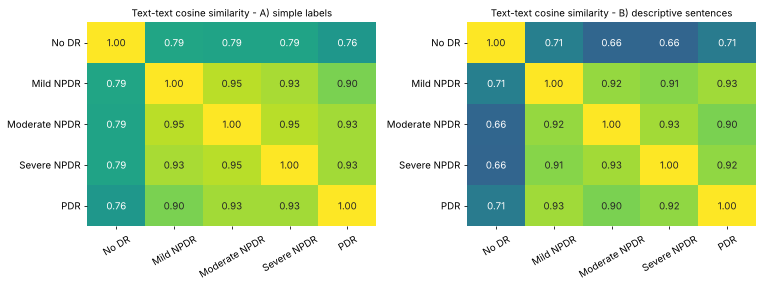

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, emb, title in zip(axes, [txt_simple, txt_desc], ["A) simple labels", "B) descriptive sentences"]):
    sns.heatmap(emb @ emb.T, annot=True, fmt=".2f", cmap="viridis", vmin=0.5, vmax=1, ax=ax,
                xticklabels=GRADE_NAMES, yticklabels=GRADE_NAMES, cbar=False)
    ax.set_title(f"Text-text cosine similarity - {title}", fontsize=10)
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/text_similarity.png"); plt.show()

<div dir="rtl">

## بخش چهارم: تشخیص پزشکی Zero-Shot

برای تصویر $x$ و جمله‌های $t_1,\dots,t_K$:

$$ s_k = \cos\big(f_{img}(x),\, f_{txt}(t_k)\big), \qquad p(k \mid x) = \mathrm{softmax}_k\!\left(\frac{s_k}{\tau}\right) = \frac{\exp(s_k/\tau)}{\sum_j \exp(s_j/\tau)} $$

که $1/\tau$ همان `logit_scale` آموزش‌دیده‌ی CLIP (برابر ۱۰۰) است. کلاس پیش‌بینی‌شده جمله‌ای است که بیشترین احتمال را دارد.

</div>

In [9]:
LOGIT_SCALE = model.logit_scale.exp().item()      # = 100 for CLIP

def zero_shot_probs(image_emb, text_emb, scale=LOGIT_SCALE):
    """Cosine similarity between images and sentences -> softmax probability of every sentence."""
    logits = scale * torch.from_numpy(image_emb) @ torch.from_numpy(text_emb).T
    return torch.softmax(logits, dim=-1).numpy()

def evaluate(probs, y_true):
    pred = probs.argmax(1)
    return {
        "Accuracy":            accuracy_score(y_true, pred),
        "Balanced accuracy":   balanced_accuracy_score(y_true, pred),
        "Macro F1":            f1_score(y_true, pred, average="macro", zero_division=0),
        "Quadratic kappa":     cohen_kappa_score(y_true, pred, weights="quadratic"),
        # binary screening task: P(any DR) = 1 - P(healthy sentence)
        "AUC (DR vs healthy)": roc_auc_score(y_true > 0, 1 - probs[:, 0]),
    }

prompt_sets = {"A) simple labels": txt_simple, "B) descriptive sentences": txt_desc, "C) descriptive ensemble": txt_ens}
probs_q = {name: zero_shot_probs(emb_q, emb) for name, emb in prompt_sets.items()}

zs_table = pd.DataFrame({name: evaluate(p, y_q) for name, p in probs_q.items()}).T
majority = np.bincount(y_q).max() / len(y_q)
print(f"query images: {len(y_q)} | majority-class accuracy: {majority:.3f} | chance (5 classes): 0.200")
zs_table.to_csv(f"{OUT_DIR}/zero_shot_results.csv")
zs_table.round(3)

query images: 400 | majority-class accuracy: 0.435 | chance (5 classes): 0.200


,Accuracy,Balanced accuracy,Macro F1,Quadratic kappa,AUC (DR vs healthy)
A) simple labels,0.142,0.130,0.116,-0.016,0.518
B) descriptive sentences,0.448,0.261,0.211,0.226,0.691
C) descriptive ensemble,0.438,0.205,0.136,0.122,0.725


<div dir="rtl">

### ۴.۱ ماتریس درهم‌ریختگی و گزارش کلاس‌ها

</div>

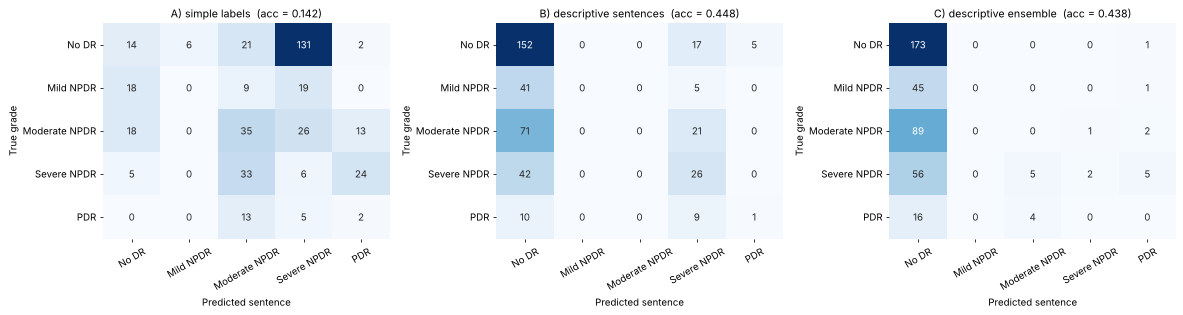

Classification report - B) descriptive sentences


,precision,recall,f1-score,support
No DR,0.481,0.874,0.620,174.000
Mild NPDR,0.000,0.000,0.000,46.000
Moderate NPDR,0.000,0.000,0.000,92.000
Severe NPDR,0.333,0.382,0.356,68.000
PDR,0.167,0.050,0.077,20.000
accuracy,0.448,0.448,0.448,0.448
macro avg,0.196,0.261,0.211,400.000
weighted avg,0.274,0.448,0.334,400.000


In [10]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
for ax, (name, p) in zip(axes, probs_q.items()):
    cm = confusion_matrix(y_q, p.argmax(1), labels=range(5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=GRADE_NAMES, yticklabels=GRADE_NAMES)
    ax.set_title(f"{name}  (acc = {accuracy_score(y_q, p.argmax(1)):.3f})", fontsize=11)
    ax.set_xlabel("Predicted sentence"); ax.set_ylabel("True grade"); ax.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/confusion_matrices.png"); plt.show()

print("Classification report - B) descriptive sentences")
rep = classification_report(y_q, probs_q["B) descriptive sentences"].argmax(1), labels=range(5),
                            target_names=GRADE_NAMES, zero_division=0, output_dict=True)
pd.DataFrame(rep).T.to_csv(f"{OUT_DIR}/classification_report_descriptive.csv")
pd.DataFrame(rep).T.round(3)

<div dir="rtl">

### ۴.۲ تفسیر یک تصویر: احتمال هر جمله‌ی توصیفی

برای چند تصویر پرس‌وجو (از هر درجه یکی)، خروجی `softmax` روی ۵ جمله‌ی توصیفی نمایش داده می‌شود. میله‌ی سبز جمله‌ی درست (برچسب چشم‌پزشک) است.

</div>

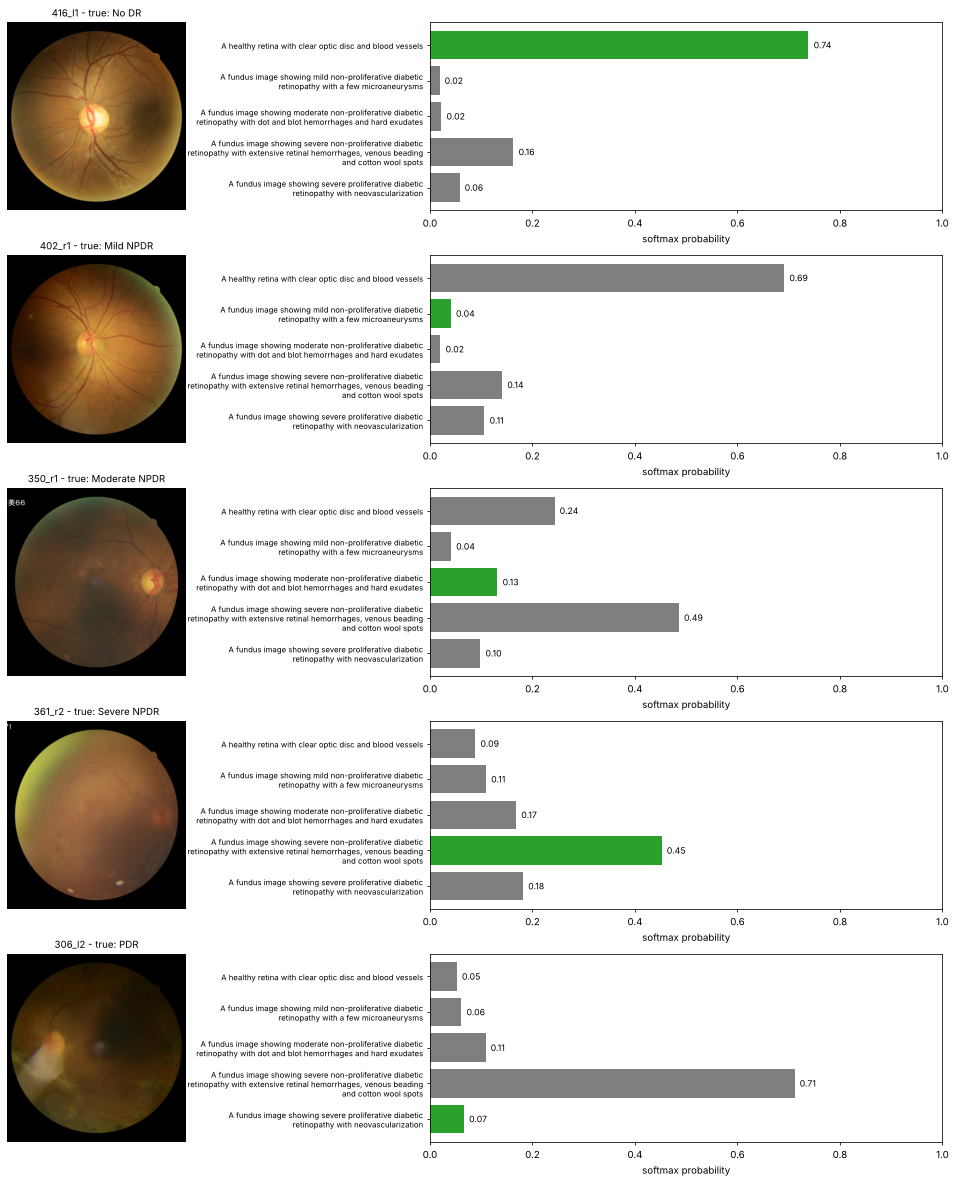

In [11]:
def short(s, width=62):
    return "\n".join(textwrap.wrap(s, width))

rng = np.random.default_rng(7)
examples = [rng.choice(np.where(y_q == g)[0]) for g in range(5)]
p_desc = probs_q["B) descriptive sentences"]

fig, axes = plt.subplots(5, 2, figsize=(14, 17), gridspec_kw={"width_ratios": [1, 2.4]})
for row, idx in enumerate(examples):
    axes[row, 0].imshow(Image.open(df_q.path[idx]).resize((336, 353))); axes[row, 0].axis("off")
    axes[row, 0].set_title(f"{df_q.image_id[idx]} - true: {GRADE_NAMES[y_q[idx]]}", fontsize=10)
    colors = ["tab:green" if k == y_q[idx] else "tab:gray" for k in range(5)]
    axes[row, 1].barh(range(5), p_desc[idx], color=colors)
    axes[row, 1].set_yticks(range(5)); axes[row, 1].set_yticklabels([short(s) for s in PROMPTS_DESC], fontsize=8)
    axes[row, 1].invert_yaxis(); axes[row, 1].set_xlim(0, 1); axes[row, 1].set_xlabel("softmax probability")
    for k, v in enumerate(p_desc[idx]):
        axes[row, 1].text(v + 0.01, k, f"{v:.2f}", va="center", fontsize=9)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/zero_shot_examples.png"); plt.show()

<div dir="rtl">

### ۴.۳ نقش دما (Temperature) در softmax

شباهت‌های کسینوسی جمله‌ها برای یک تصویر بسیار به هم نزدیک‌اند (اختلاف در حد چند صدم). ضریب `logit_scale = 100` این اختلاف‌های کوچک را
به توزیع احتمال معنادار تبدیل می‌کند. تغییر دما کلاس برنده را عوض نمی‌کند، فقط «اطمینان» توزیع را تغییر می‌دهد.

</div>

In [12]:
idx = examples[0]
sims = emb_q[idx] @ txt_desc.T
temp_table = pd.DataFrame({"cosine similarity": sims}, index=GRADE_NAMES)
for scale in [1, 10, 100]:
    temp_table[f"softmax (scale={scale})"] = zero_shot_probs(emb_q[idx:idx + 1], txt_desc, scale)[0]
print("image:", df_q.image_id[idx], "| true grade:", GRADE_NAMES[y_q[idx]])
temp_table.round(3)

image: 416_l1 | true grade: No DR


,cosine similarity,softmax (scale=1),softmax (scale=10),softmax (scale=100)
No DR,0.372,0.205,0.248,0.739
Mild NPDR,0.335,0.197,0.172,0.019
Moderate NPDR,0.337,0.197,0.175,0.022
Severe NPDR,0.357,0.201,0.213,0.163
PDR,0.347,0.199,0.192,0.058


<div dir="rtl">

## بخش پنجم: جستجوی معنایی متن → تصویر (Text-to-Image Retrieval)

حالا جهت مقایسه برعکس می‌شود: یک **توصیف متنی** داده می‌شود و ۱۲۰۰ تصویر گالری بر اساس شباهت کسینوسی با آن مرتب می‌شوند.
علاوه بر ۵ جمله‌ی توصیفی کلاس‌ها، دو پرس‌وجوی آزاد هم تعریف شده که مستقیماً برچسب کلاس نیستند:

- توصیف یک **ضایعه** (خونریزی و اگزودا) → تصاویر مرتبط: درجه‌ی ۲ به بالا
- توصیف **کیفیت تصویر** (تار و دارای آرتیفکت) → تصاویر مرتبط: `Overall quality = 0`

معیارها: **Precision@5** و **Precision@10** (چه کسری از نتایج اول مرتبط‌اند)، **Average Precision** و برای مقایسه **Base rate**
(کسر تصاویر مرتبط در کل گالری = دقت مورد انتظار یک جستجوی تصادفی).

</div>

In [13]:
q_g = df_g.quality.values
QUERIES = [(PROMPTS_DESC[g], y_g == g, f"grade {g} ({GRADE_NAMES[g]})") for g in range(5)] + [
    ("A retina with many red hemorrhages and yellow hard exudates", y_g >= 2, "grade >= 2 (lesions visible)"),
    ("A blurry, poor quality fundus photograph with artifacts and uneven illumination", q_g == 0, "poor image quality"),
]

def retrieve(text, gallery_emb, k=10):
    """Rank the gallery images by cosine similarity to a sentence."""
    sims = gallery_emb @ encode_texts([text])[0]
    order = np.argsort(-sims)
    return order[:k], sims

rows = []
for text, relevant, rel_name in QUERIES:
    order, sims = retrieve(text, emb_g, k=len(emb_g))
    rows.append({"query": text, "relevant images": rel_name, "base rate": relevant.mean(),
                 "P@5": relevant[order[:5]].mean(), "P@10": relevant[order[:10]].mean(),
                 "AP": average_precision_score(relevant, sims)})
retr_table = pd.DataFrame(rows)
retr_table.to_csv(f"{OUT_DIR}/text_to_image_retrieval.csv", index=False)
print("mean over queries:  base rate = %.3f | P@5 = %.3f | P@10 = %.3f | mAP = %.3f"
      % tuple(retr_table[["base rate", "P@5", "P@10", "AP"]].mean()))
retr_table.round(3)

mean over queries:  base rate = 0.279 | P@5 = 0.514 | P@10 = 0.486 | mAP = 0.308


,query,relevant images,base rate,P@5,P@10,AP
0,A healthy retina with clear optic disc and blood vessels,grade 0 (No DR),0.450,1.0,0.8,0.488
1,A fundus image showing mild non-proliferative diabetic retinopathy with a few microaneurysms,grade 1 (Mild NPDR),0.117,0.0,0.3,0.116
2,A fundus image showing moderate non-proliferative diabetic retinopathy with dot and blot hemorrhages and hard exudates,grade 2 (Moderate NPDR),0.195,0.2,0.2,0.211
3,"A fundus image showing severe non-proliferative diabetic retinopathy with extensive retinal hemorrhages, venous beading and cotton wool spots",grade 3 (Severe NPDR),0.178,0.8,0.6,0.313
4,A fundus image showing severe proliferative diabetic retinopathy with neovascularization,grade 4 (PDR),0.060,0.2,0.2,0.075
5,A retina with many red hemorrhages and yellow hard exudates,grade >= 2 (lesions visible),0.433,1.0,0.9,0.454
6,"A blurry, poor quality fundus photograph with artifacts and uneven illumination",poor image quality,0.520,0.4,0.4,0.498


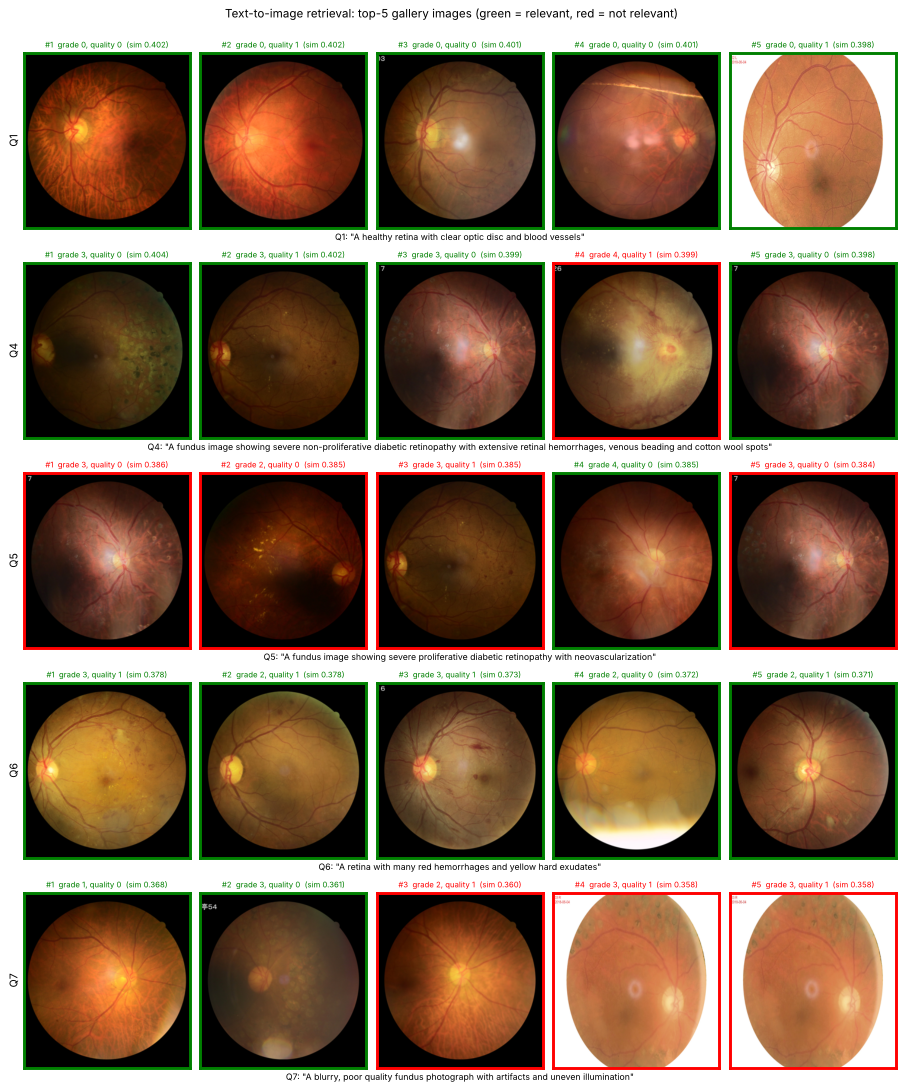

In [14]:
show = [0, 3, 4, 5, 6]                                   # queries to visualise
fig, axes = plt.subplots(len(show), 5, figsize=(13, 3.1 * len(show)))
for r, qi in enumerate(show):
    text, relevant, rel_name = QUERIES[qi]
    top, sims = retrieve(text, emb_g, k=5)
    for c, idx in enumerate(top):
        ax = axes[r, c]
        ax.imshow(Image.open(df_g.path[idx]).resize((280, 294)))
        ok = bool(relevant[idx])
        ax.set_title(f"#{c + 1}  grade {y_g[idx]}, quality {q_g[idx]}  (sim {sims[idx]:.3f})",
                     fontsize=8, color="green" if ok else "red")
        ax.set_xticks([]); ax.set_yticks([])
        for sp in ax.spines.values():
            sp.set_edgecolor("green" if ok else "red"); sp.set_linewidth(3)
    axes[r, 0].set_ylabel(f"Q{qi + 1}", fontsize=11)
    axes[r, 2].set_xlabel(f'Q{qi + 1}: "{text}"', fontsize=9)
plt.suptitle("Text-to-image retrieval: top-5 gallery images (green = relevant, red = not relevant)", y=1.0)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/text_to_image_retrieval.png"); plt.show()

<div dir="rtl">

## بخش ششم: جستجوی تصویر → تصویر و مقایسه با روش‌های نظارت‌شده

برای اینکه بدانیم ضعف/قوت نتایج از **رمزگذار تصویر** است یا از **تطابق متن و تصویر**، از همان بردارهای تصویر CLIP به دو روش دیگر استفاده می‌کنیم:

- **k-NN (جستجوی تصویر → تصویر):** برای هر تصویر پرس‌وجو، ۱۰ تصویر شبیه‌تر در گالری پیدا می‌شود و درجه‌ی اکثریت آن‌ها پیش‌بینی است.
- **Linear Probe:** یک رگرسیون لجستیک روی بردارهای گالری (با برچسب) آموزش می‌بیند و روی پرس‌وجوها آزمایش می‌شود.

این دو روش از برچسب‌های گالری استفاده می‌کنند (دیگر Zero-Shot نیستند) و سقف قابل‌دستیابی با ویژگی‌های ثابت CLIP را نشان می‌دهند.

</div>

In [15]:
K = 10
sim_qg = emb_q @ emb_g.T                                   # query x gallery cosine similarity
nn_idx = np.argsort(-sim_qg, axis=1)[:, :K]
knn_votes = np.stack([np.bincount(y_g[row], minlength=5) for row in nn_idx])
knn_probs = knn_votes / K

probe = LogisticRegression(C=10, max_iter=2000).fit(emb_g, y_g)
probe_probs = probe.predict_proba(emb_q)

summary = zs_table.copy()
summary.index = ["Zero-shot - " + n for n in summary.index]
summary.loc[f"Image-to-image k-NN (k={K}, uses gallery labels)"] = evaluate(knn_probs, y_q)
summary.loc["Linear probe on CLIP features (uses gallery labels)"] = evaluate(probe_probs, y_q)
summary.to_csv(f"{OUT_DIR}/summary.csv")
summary.round(3)

,Accuracy,Balanced accuracy,Macro F1,Quadratic kappa,AUC (DR vs healthy)
Zero-shot - A) simple labels,0.142,0.130,0.116,-0.016,0.518
Zero-shot - B) descriptive sentences,0.448,0.261,0.211,0.226,0.691
Zero-shot - C) descriptive ensemble,0.438,0.205,0.136,0.122,0.725
"Image-to-image k-NN (k=10, uses gallery labels)",0.545,0.375,0.392,0.482,0.842
Linear probe on CLIP features (uses gallery labels),0.635,0.465,0.481,0.706,0.905


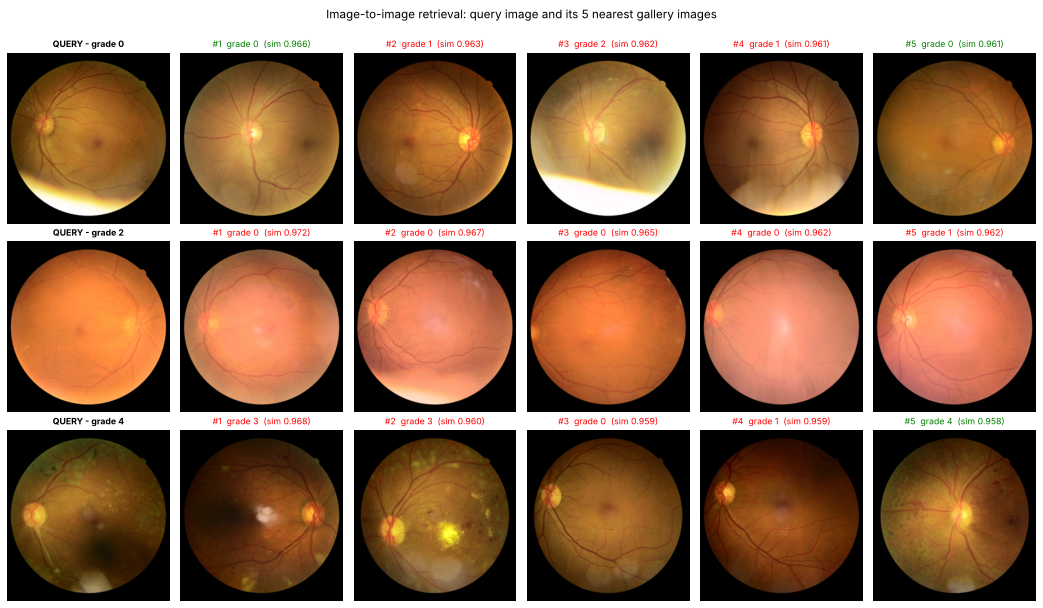

In [16]:
rng = np.random.default_rng(3)
picks = [rng.choice(np.where(y_q == g)[0]) for g in (0, 2, 4)]
fig, axes = plt.subplots(len(picks), 6, figsize=(15, 2.9 * len(picks)))
for r, qi in enumerate(picks):
    axes[r, 0].imshow(Image.open(df_q.path[qi]).resize((280, 294)))
    axes[r, 0].set_title(f"QUERY - grade {y_q[qi]}", fontsize=9, fontweight="bold")
    for c, gi in enumerate(nn_idx[qi, :5], start=1):
        axes[r, c].imshow(Image.open(df_g.path[gi]).resize((280, 294)))
        axes[r, c].set_title(f"#{c}  grade {y_g[gi]}  (sim {sim_qg[qi, gi]:.3f})", fontsize=9,
                             color="green" if y_g[gi] == y_q[qi] else "red")
    for ax in axes[r]:
        ax.axis("off")
plt.suptitle("Image-to-image retrieval: query image and its 5 nearest gallery images", y=1.0)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/image_to_image_retrieval.png"); plt.show()

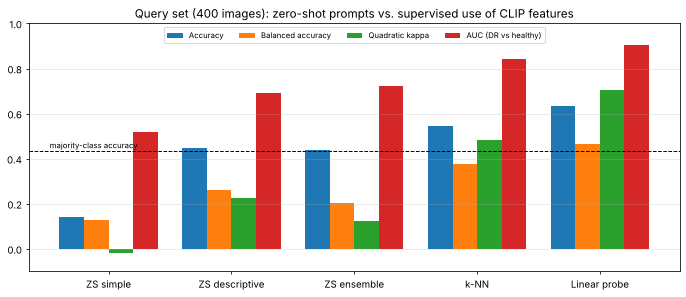

In [17]:
ax = summary[["Accuracy", "Balanced accuracy", "Quadratic kappa", "AUC (DR vs healthy)"]].plot.bar(figsize=(12, 4.6), width=0.8)
ax.axhline(majority, color="k", ls="--", lw=1); ax.text(-0.48, majority + 0.012, "majority-class accuracy", ha="left", fontsize=8)
ax.set_xticklabels(["ZS simple", "ZS descriptive", "ZS ensemble", "k-NN", "Linear probe"], rotation=0)
ax.set_ylim(-0.1, 1); ax.set_title("Query set (400 images): zero-shot prompts vs. supervised use of CLIP features")
ax.legend(ncol=4, fontsize=8, loc="upper center"); ax.grid(axis="y", alpha=0.3)
plt.savefig(f"{OUT_DIR}/summary.png"); plt.show()

<div dir="rtl">

## ۷. جمع‌بندی

**تشخیص Zero-Shot روی ۴۰۰ تصویر پرس‌وجو (۵ درجه‌ی رتینوپاتی):**

| روش | Accuracy | Balanced Acc. | Quadratic κ | AUC (بیمار/سالم) |
|---|---|---|---|---|
| A) برچسب ساده | 14.3% | 13.0% | −0.02 | 0.518 |
| B) جمله‌ی توصیفی پزشکی | **44.8%** | **26.1%** | **0.23** | 0.691 |
| C) مجموعه‌ی توصیف‌ها | 43.8% | 20.5% | 0.12 | **0.725** |
| k-NN تصویر → تصویر (با برچسب گالری) | 54.5% | 37.5% | 0.48 | 0.842 |
| Linear Probe (با برچسب گالری) | 63.5% | 46.5% | 0.71 | 0.905 |

- **توصیف پزشکی مهم است:** با برچسب‌های ساده، CLIP عملاً تصادفی (و حتی بدتر از حدس کلاس اکثریت ۴۳٫۵٪) عمل می‌کند و بیشتر تصاویر سالم را
  «severe retinopathy» می‌نامد؛ AUC آن ۰٫۵۲ است. با جمله‌های توصیفی، دقت از ۱۴٪ به ۴۵٪ و AUC به ۰٫۶۹ می‌رسد؛ یعنی واژگان بالینی
  (optic disc، hemorrhage، exudate، ...) جمله را به ناحیه‌ی درست‌تری از فضای مشترک می‌برند.
- **اما Zero-Shot برای درجه‌بندی ریز کافی نیست:** مدل تقریباً فقط بین دو جمله‌ی «سالم» و «Severe NPDR» انتخاب می‌کند و درجه‌های ۱ و ۲ را هرگز
  پیش‌بینی نمی‌کند (ماتریس درهم‌ریختگی). تفاوت این درجه‌ها ضایعات بسیار ریز (میکروآنوریسم) است که در ورودی ۲۲۴×۲۲۴ تقریباً دیده نمی‌شوند و
  در داده‌ی آموزشی عمومی CLIP هم زوج تصویر-متنِ کافی برای آن‌ها وجود نداشته است. Prompt Ensemble تفکیک بیمار/سالم را بهتر کرد (AUC = 0.72)
  ولی پیش‌بینی‌ها را بیشتر به سمت کلاس «سالم» برد.
- **جستجوی معنایی متن → تصویر** بهتر از طبقه‌بندی عمل می‌کند: میانگین P@5 برابر ۰٫۵۱ در مقابل Base rate برابر ۰٫۲۸. برای توصیف‌های
  «شبکیه‌ی سالم» (P@5 = 1.0)، «Severe NPDR» (0.8) و «خونریزی و اگزودا» (1.0) نتایج اول تقریباً همه مرتبط‌اند؛ ولی برای Mild NPDR، PDR و
  توصیف کیفیت تصویر، نتایج در حد تصادفی است.
- **ویژگی‌های تصویری CLIP اطلاعات بیماری را دارند:** با همان بردارها، k-NN و Linear Probe به دقت ۵۵٪ و ۶۴٪ (κ = 0.71، AUC = 0.91) می‌رسند.
  پس گلوگاه اصلی، **هم‌ترازی متن پزشکی با تصویر** است نه رمزگذار تصویر؛ راه بهبود، مدل‌های CLIP تخصصی پزشکی (مانند BiomedCLIP یا FLAIR برای
  شبکیه)، ورودی با تفکیک‌پذیری بالاتر و Fine-tune / Prompt Learning با تعداد کمی نمونه‌ی برچسب‌دار است.

> این سیستم فقط یک تمرین آموزشی است و برای تشخیص بالینی قابل استفاده نیست.

</div>